# Notebook for comparing the isopycnal production fraction

In [49]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cmocean.cm as cmo
import json

## Production colorbar settings

In [ ]:
# Edit these limits to change every production panel for that tracer.
# Each pair is (minimum, maximum), shared by AMF and Espe, iso and dia.
CT_PRODUCTION_LIMITS = (1e-14, 1e-6)  # K² s⁻¹
SA_PRODUCTION_LIMITS = (1e-16, 1e-8)  # (g kg⁻¹)² s⁻¹
PRODUCTION_CMAP = cmo.balance


## Load datasets

In [6]:
# my estimates
ds_pbar_grid = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grid_var.nc')
ds_pbar_grad = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grad_clip_mask.nc')
ds_pbar_grid = ds_pbar_grid.assign_coords(LON_left = ds_pbar_grad.LON_left,LAT_left = ds_pbar_grad.LAT_left)
ds_amf = xr.merge([ds_pbar_grid, ds_pbar_grad.drop_vars({'DENSITY'})])

In [19]:
ds_espe = xr.open_dataset("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc", engine="netcdf4")
ds_espe.attrs = json.loads(ds_espe.attrs["density_grid_attrs_json"])

## Fraction Comparison Plots

In [47]:
ds_amf

<xarray.Dataset>
Dimensions:          (PRESSURE_mean: 1001, LON: 120, LAT: 60, LON_left: 120,
                      LAT_left: 60)
Coordinates:
  * PRESSURE_mean    (PRESSURE_mean) int64 0 2 4 6 8 ... 1994 1996 1998 2000
  * LON              (LON) float64 -178.5 -175.5 -172.5 ... 172.5 175.5 178.5
  * LAT              (LAT) float64 -88.5 -85.5 -82.5 -79.5 ... 82.5 85.5 88.5
  * LON_left         (LON_left) float64 -180.0 -177.0 -174.0 ... 174.0 177.0
  * LAT_left         (LAT_left) float64 -90.0 -87.0 -84.0 ... 81.0 84.0 87.0
Data variables: (12/57)
    CT_sort          (PRESSURE_mean, LON, LAT) float64 ...
    SA_sort          (PRESSURE_mean, LON, LAT) float64 ...
    SPICE_sort       (PRESSURE_mean, LON, LAT) float64 ...
    DENSITY          (PRESSURE_mean, LON, LAT) float64 ...
    CT_sort_m        (PRESSURE_mean, LON, LAT) float64 ...
    SA_sort_m        (PRESSURE_mean, LON, LAT) float64 ...
    ...               ...
    F_SPICE_y        (PRESSURE_mean, LON, LAT) float64 ...
    F_SPICE_xy       (PRESSURE_mean, LON, LAT) float64 ...
    Cp               (PRESSURE_mean, LON, LAT) float64 ...
    F_heat_x         (PRESSURE_mean, LON, LAT) float64 ...
    F_heat_y         (PRESSURE_mean, LON, LAT) float64 ...
    F_heat_xy        (PRESSURE_mean, LON, LAT) float64 ...

In [20]:
ds_espe

<xarray.Dataset>
Dimensions:                     (pressure_bin: 41, latitude: 60,
                                 longitude: 120, bounds: 2,
                                 neutral_density_bin: 577)
Coordinates:
  * pressure_bin                (pressure_bin) float64 25.0 75.0 ... 2.025e+03
  * latitude                    (latitude) float64 -88.5 -85.5 ... 85.5 88.5
  * longitude                   (longitude) float64 -178.5 -175.5 ... 178.5
  * neutral_density_bin         (neutral_density_bin) float64 0.025 ... 28.83
Dimensions without coordinates: bounds
Data variables: (12/57)
    pressure_bin_bounds         (pressure_bin, bounds) float64 ...
    latitude_bounds             (latitude, bounds) int64 ...
    longitude_bounds            (longitude, bounds) int64 ...
    Krho_pressure               (pressure_bin, latitude, longitude) float64 ...
    Krho_sum_pressure           (pressure_bin, latitude, longitude) float64 ...
    Krho_count_pressure         (pressure_bin, latitude, longitude) int64 ...
    ...                          ...
    PSdia_count_density         (neutral_density_bin, latitude, longitude) int64 ...
    PSiso_density               (neutral_density_bin, latitude, longitude) float64 ...
    PSiso_sum_density           (neutral_density_bin, latitude, longitude) float64 ...
    PSiso_count_density         (neutral_density_bin, latitude, longitude) int64 ...
    observation_count_density   (neutral_density_bin, latitude, longitude) int64 ...
    profile_count_density       (neutral_density_bin, latitude, longitude) int64 ...
Attributes: (12/19)
    horizontal_resolution_degrees:  3.0
    vertical_bin_width:             0.05
    bin_rule:                       lower-inclusive, upper-exclusive; longitu...
    vertical_range:                 all observed finite coordinate bins, incl...
    weighting:                      one vote per finite Zfs observation, not ...
    pressure_coordinate:            mean pressure where abs(Zmeas-Zfs)<25 m, ...
    ...                             ...
    sampling_note:                  200-m mixing windows overlap at 50-m spac...
    source_manifest:                /swot/SUM05/amf2288/argo_mixing/global_re...
    source_manifest_sha256:         50baf86caf1b60a7c0197b3cf562f45cf87dc1867...
    signature:                      5fb0cf52dd6b313b89a1ba7775d1b984a2452fcde...
    accepted_profiles:              1117885
    source_partitions:              25686

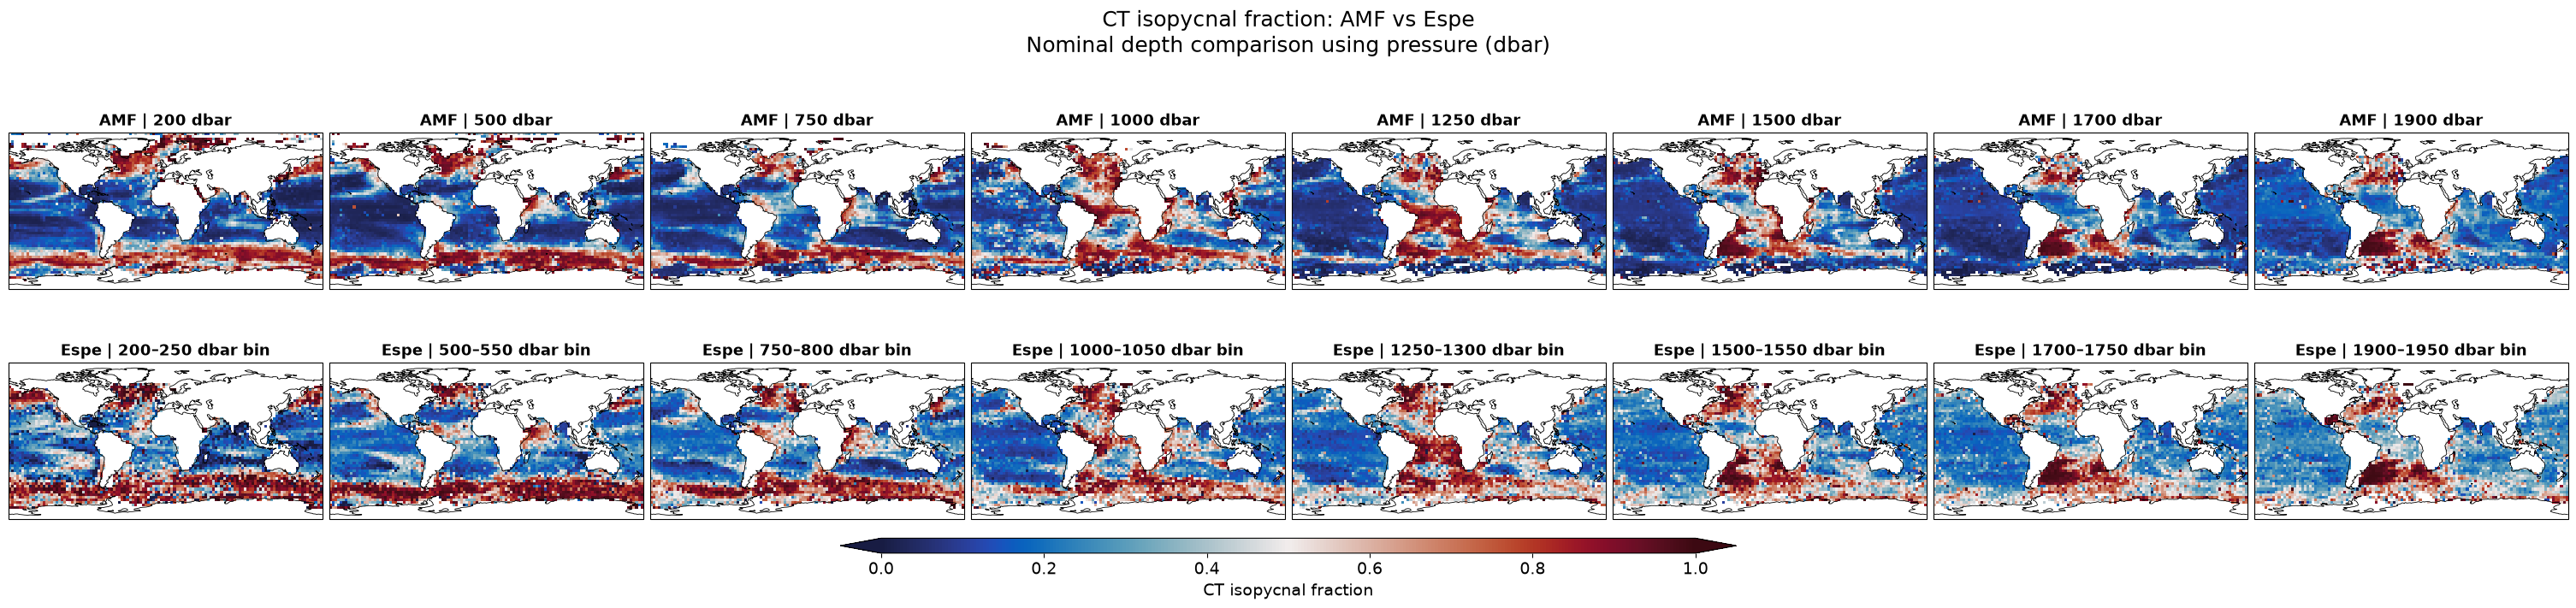

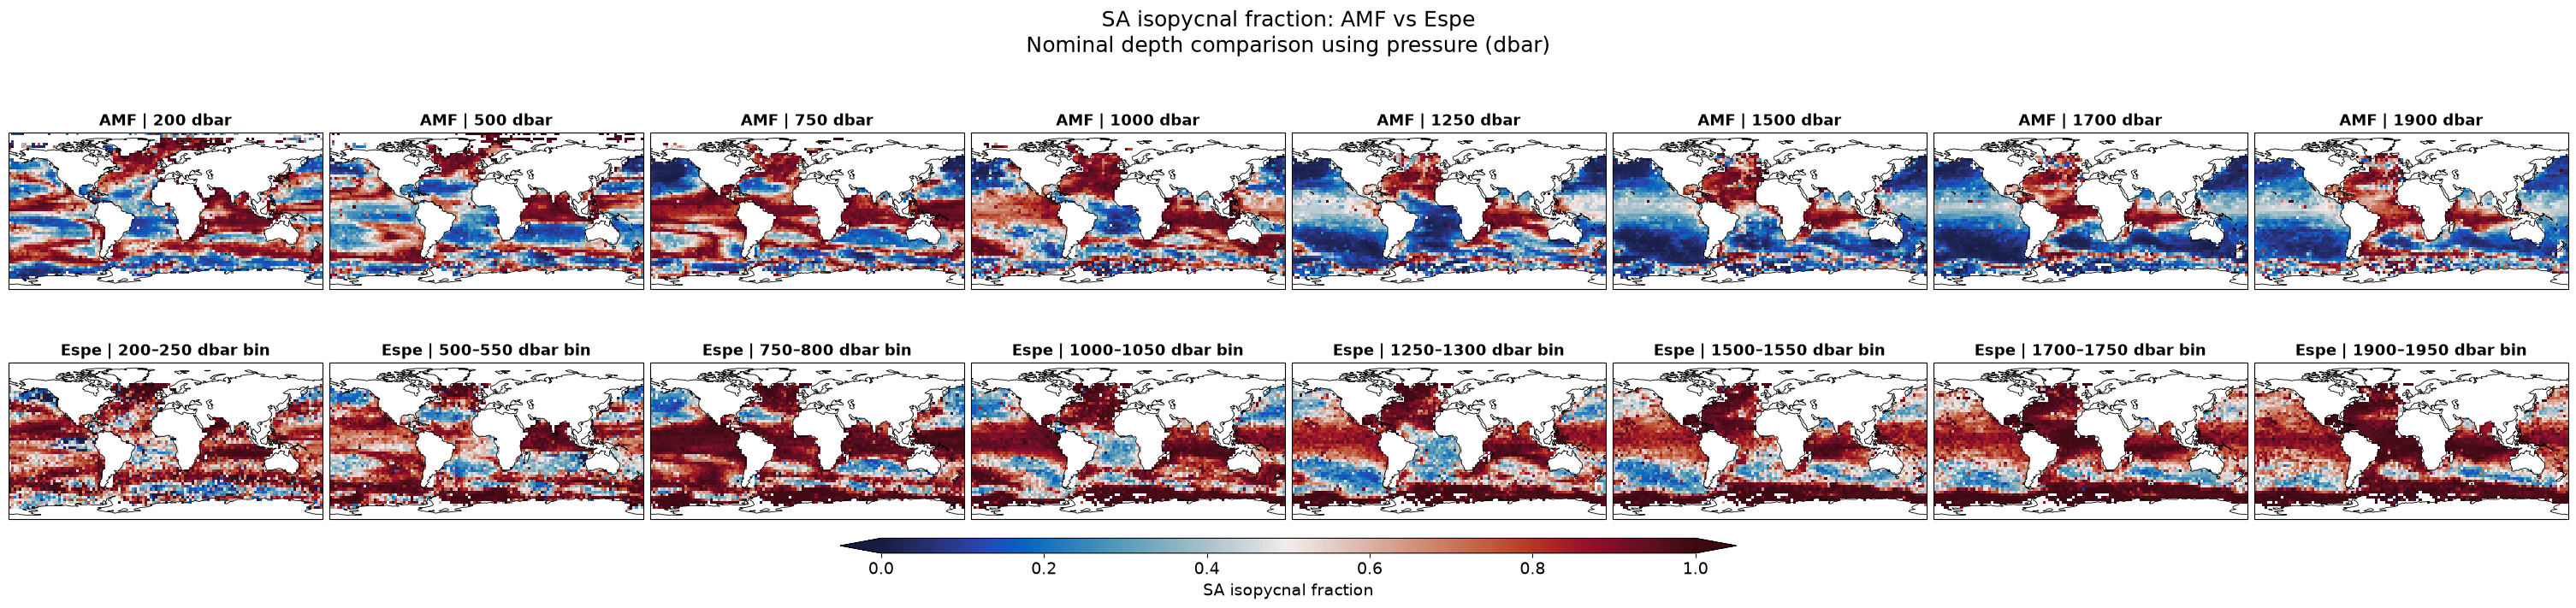

In [ ]:
depths = [200, 500, 750, 1000, 1250, 1500, 1700, 1900]
# These products use pressure coordinates: match nominal depths numerically
# in dbar and label the actual AMF level and Espe pressure-bin bounds.
figures = {}
map_axes = {}
for tracer, amf_name, production_name, dissipation_name in [
    ("CT", "CT_meso_frac", "Piso_pressure", "chi_pressure"),
    ("SA", "SA_meso_frac", "PSiso_pressure", "chiS_pressure"),
]:
    fig, axes = plt.subplots(
        2, len(depths), figsize=(30, 7),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f"{tracer} isopycnal fraction: AMF vs Espe\n"
        "Nominal depth comparison using pressure (dbar)",
        fontsize=18,
    )
    for col, depth in enumerate(depths):
        amf_level = ds_amf.sel(PRESSURE_mean=depth, method="nearest")
        espe_level = ds_espe.sel(pressure_bin=depth, method="nearest")
        # Ratio of gridded mean production/dissipation; mask nonpositive denominators.
        dissipation = espe_level[dissipation_name]
        espe_fraction = espe_level[production_name] / dissipation.where(dissipation > 0)
        amf_pressure = float(amf_level.PRESSURE_mean)
        espe_lower, espe_upper = espe_level.pressure_bin_bounds.values

        panels = [
            (axes[0, col], amf_level[amf_name], "LON", "LAT",
             f"AMF | {amf_pressure:g} dbar"),
            (axes[1, col], espe_fraction, "longitude", "latitude",
             f"Espe | {espe_lower:g}–{espe_upper:g} dbar bin"),
        ]
        for ax, field, lon, lat, title in panels:
            if bool(field.notnull().any()):
                mesh = field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=cmo.balance, vmin=0, vmax=1, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, "No finite estimates\nin this pressure bin",
                    transform=ax.transAxes, ha="center", va="center", fontsize=12,
                    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=0.6)
            ax.set_title(title, fontsize=13)

    fig.colorbar(
        mesh, ax=axes.ravel().tolist(), orientation="horizontal",
        fraction=0.04, pad=0.04, shrink=0.35, aspect=60,
        label=f"{tracer} isopycnal fraction", extend="both",
    )
    figures[tracer] = fig
    map_axes[tracer] = axes

plt.show()


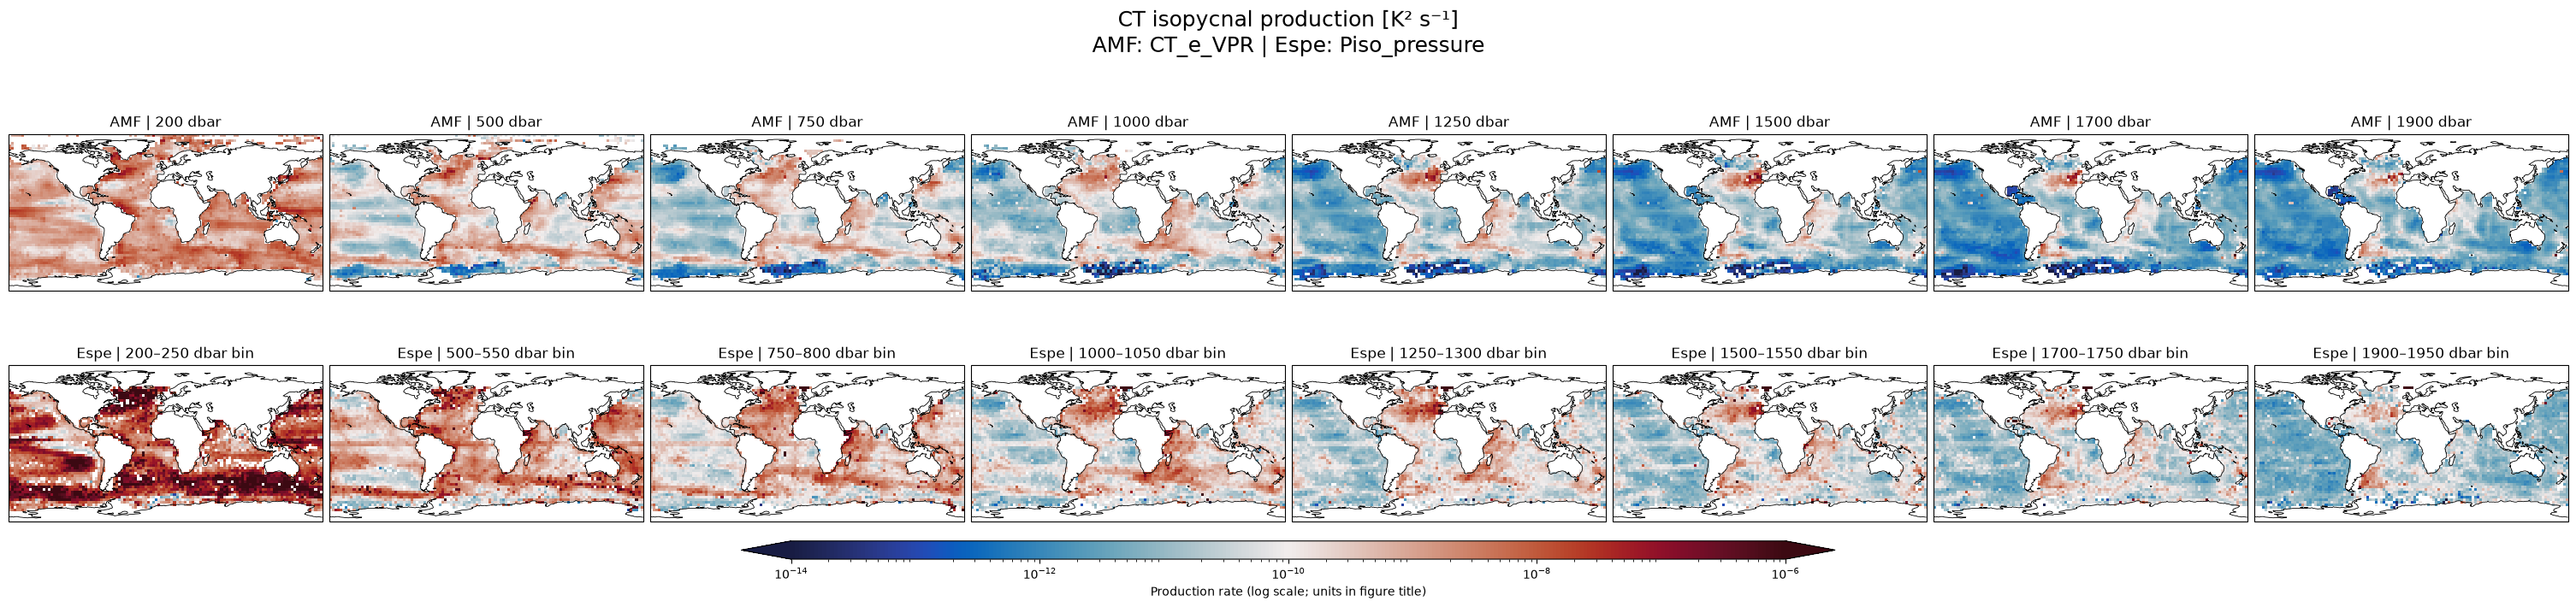

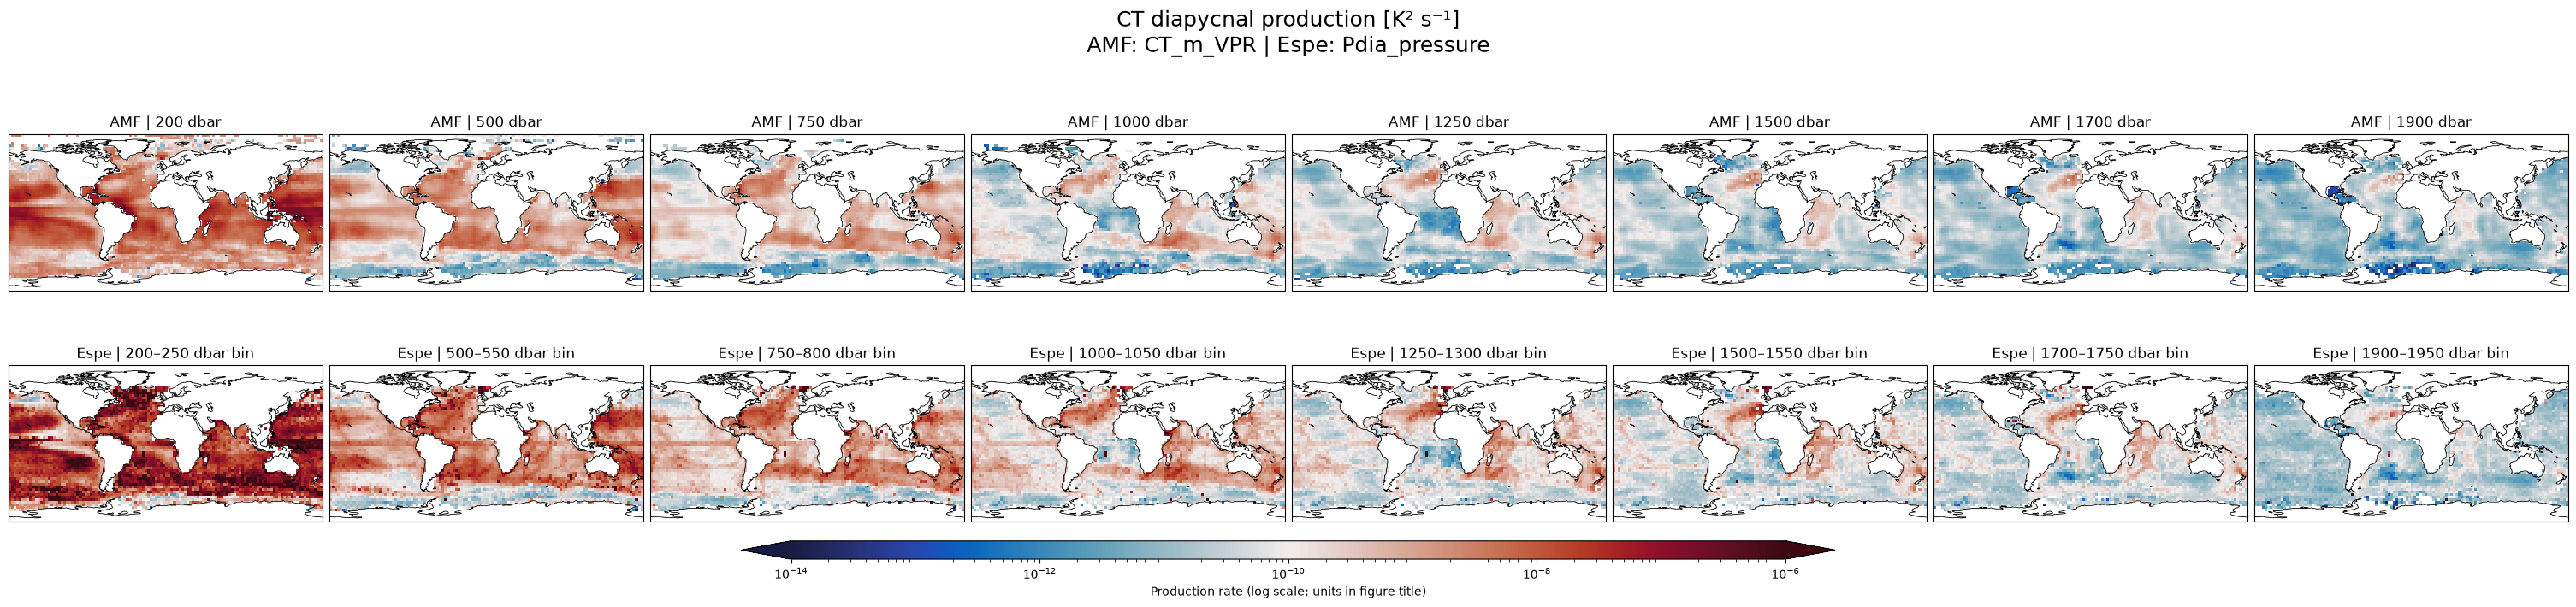

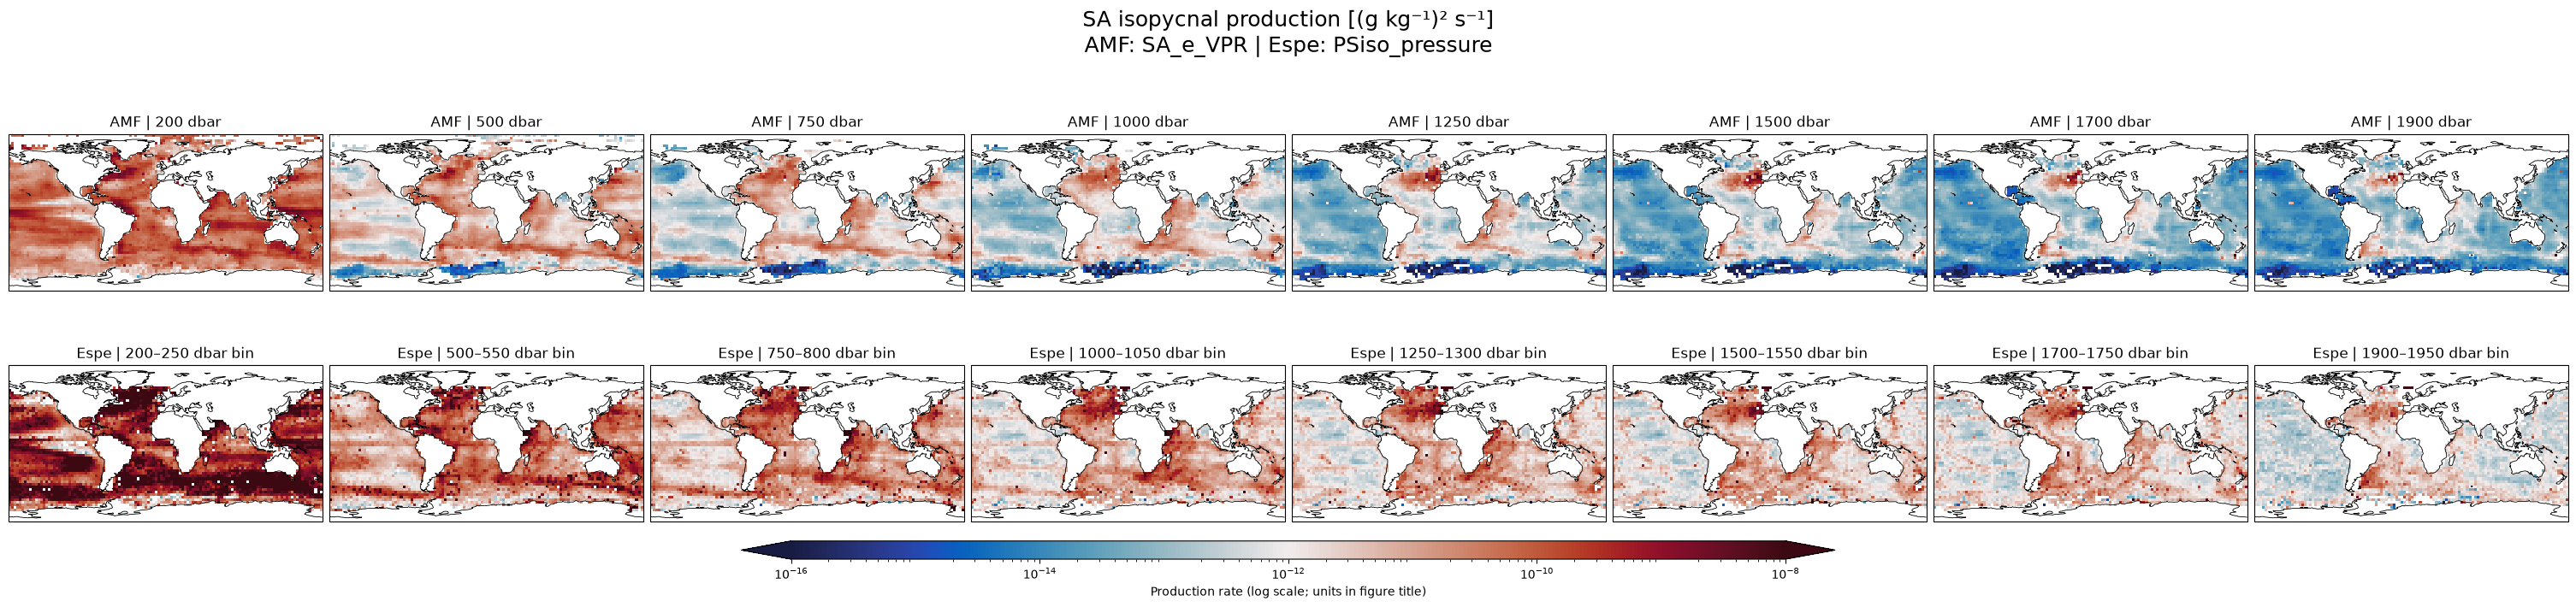

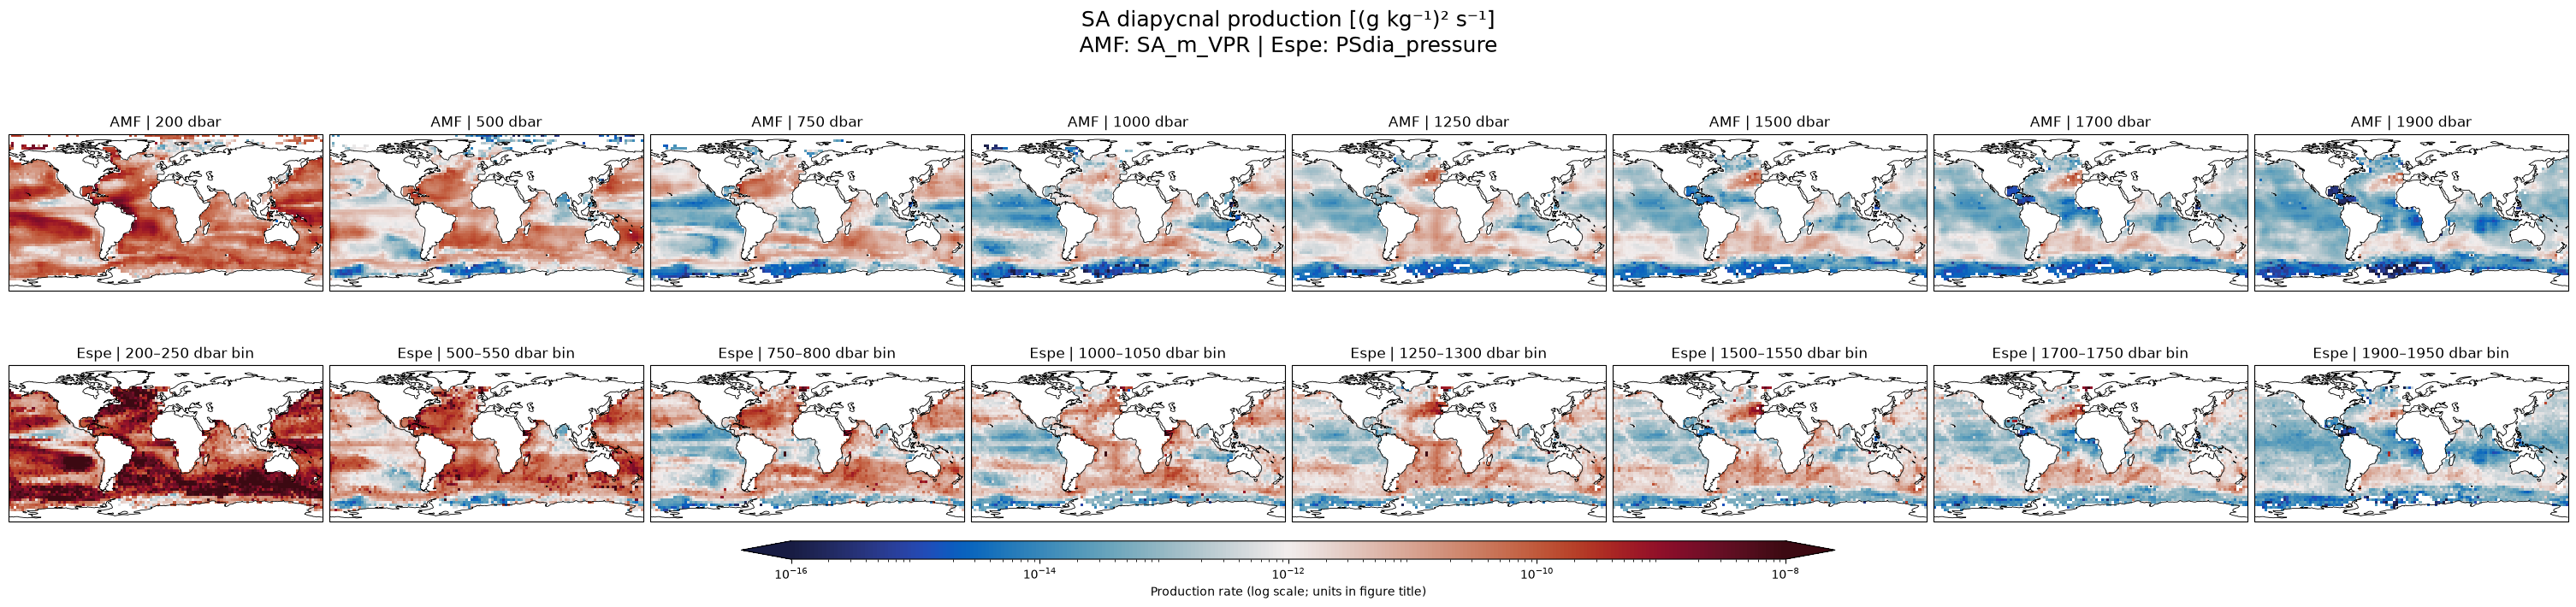

In [ ]:
# Settings at the top take precedence; use defaults if that cell has not run yet.
CT_PRODUCTION_LIMITS = globals().get("CT_PRODUCTION_LIMITS", (1e-14, 1e-6))
SA_PRODUCTION_LIMITS = globals().get("SA_PRODUCTION_LIMITS", (1e-16, 1e-8))
PRODUCTION_CMAP = globals().get("PRODUCTION_CMAP", cmo.balance)

# Shared logarithmic scales from the settings cell at the top.
production_norms = {
    "CT": colors.LogNorm(vmin=CT_PRODUCTION_LIMITS[0], vmax=CT_PRODUCTION_LIMITS[1]),
    "SA": colors.LogNorm(vmin=SA_PRODUCTION_LIMITS[0], vmax=SA_PRODUCTION_LIMITS[1]),
}
production_figures = {}
production_axes = {}

for tracer, metric, amf_name, espe_name, units in [
    ("CT", "CT isopycnal production", "CT_e_VPR", "Piso_pressure", "K² s⁻¹"),
    ("CT", "CT diapycnal production", "CT_m_VPR", "Pdia_pressure", "K² s⁻¹"),
    ("SA", "SA isopycnal production", "SA_e_VPR", "PSiso_pressure", "(g kg⁻¹)² s⁻¹"),
    ("SA", "SA diapycnal production", "SA_m_VPR", "PSdia_pressure", "(g kg⁻¹)² s⁻¹"),
]:
    production_norm = production_norms[tracer]
    production_ticks = np.geomspace(production_norm.vmin, production_norm.vmax, 5)
    fig, axes = plt.subplots(
        2, len(depths), figsize=(30, 7),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f"{metric} [{units}]\nAMF: {amf_name} | Espe: {espe_name}",
        fontsize=18,
    )
    for col, depth in enumerate(depths):
        amf_level = ds_amf.sel(PRESSURE_mean=depth, method="nearest")
        espe_level = ds_espe.sel(pressure_bin=depth, method="nearest")
        amf_pressure = float(amf_level.PRESSURE_mean)
        espe_lower, espe_upper = espe_level.pressure_bin_bounds.values
        panels = [
            (axes[0, col], amf_level[amf_name], "LON", "LAT",
             f"AMF | {amf_pressure:g} dbar"),
            (axes[1, col], espe_level[espe_name], "longitude", "latitude",
             f"Espe | {espe_lower:g}–{espe_upper:g} dbar bin"),
        ]
        for ax, field, lon, lat, title in panels:
            # LogNorm displays positive values; the source datasets are not modified.
            field = field.where(field > 0)
            if bool(field.notnull().any()):
                field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=PRODUCTION_CMAP, norm=production_norm, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, "No positive estimates\nin this pressure bin",
                    transform=ax.transAxes, ha="center", va="center", fontsize=11,
                    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=0.6)
            ax.set_title(title, fontsize=12)

    fig.colorbar(
        ScalarMappable(norm=production_norm, cmap=PRODUCTION_CMAP),
        ax=axes.ravel().tolist(), orientation="horizontal",
        fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
        ticks=production_ticks, extend="both",
        label="Production rate (log scale; units in figure title)",
    )
    production_figures[metric] = fig
    production_axes[metric] = axes

plt.show()


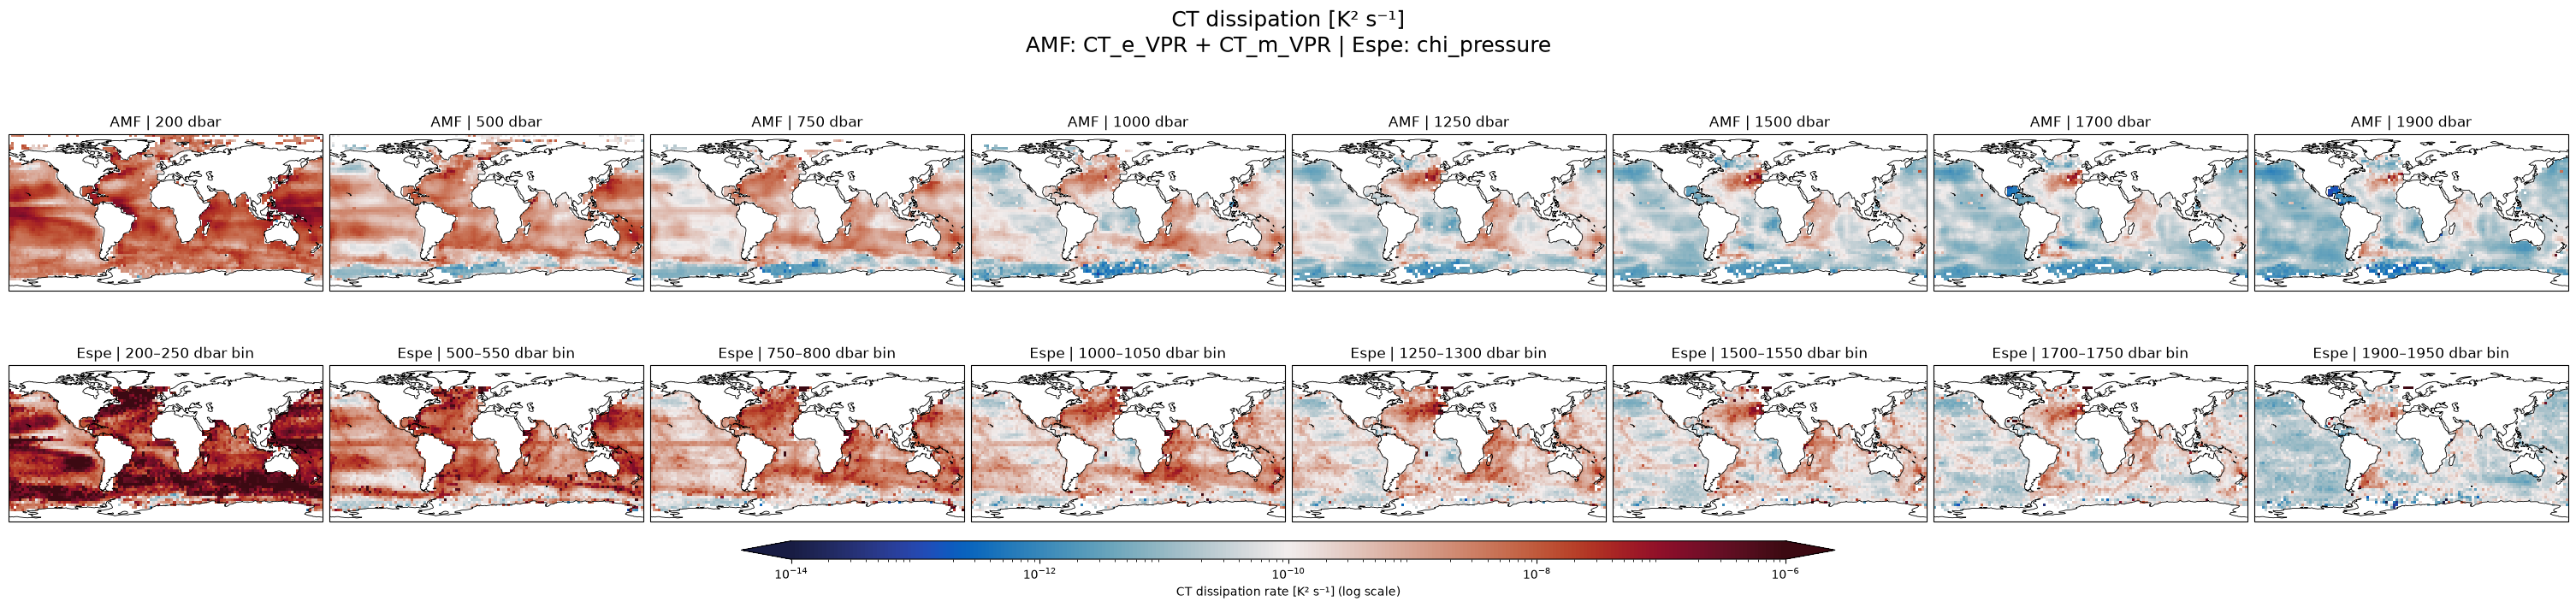

In [ ]:
# CT variance dissipation: AMF total production versus Espe chi.
# Use the CT color settings above, with the same first-run defaults.
CT_PRODUCTION_LIMITS = globals().get("CT_PRODUCTION_LIMITS", (1e-14, 1e-6))
PRODUCTION_CMAP = globals().get("PRODUCTION_CMAP", cmo.balance)
ct_dissipation_norm = colors.LogNorm(
    vmin=CT_PRODUCTION_LIMITS[0], vmax=CT_PRODUCTION_LIMITS[1],
)
ct_dissipation_ticks = np.geomspace(*CT_PRODUCTION_LIMITS, 5)

ct_dissipation_fig, ct_dissipation_axes = plt.subplots(
    2, len(depths), figsize=(30, 7),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
ct_dissipation_fig.suptitle(
    "CT dissipation [K² s⁻¹]\n"
    "AMF: CT_e_VPR + CT_m_VPR | Espe: chi_pressure",
    fontsize=18,
)
for col, depth in enumerate(depths):
    amf_level = ds_amf.sel(PRESSURE_mean=depth, method="nearest")
    espe_level = ds_espe.sel(pressure_bin=depth, method="nearest")
    amf_dissipation = amf_level.CT_e_VPR + amf_level.CT_m_VPR
    amf_pressure = float(amf_level.PRESSURE_mean)
    espe_lower, espe_upper = espe_level.pressure_bin_bounds.values
    panels = [
        (ct_dissipation_axes[0, col], amf_dissipation, "LON", "LAT",
         f"AMF | {amf_pressure:g} dbar"),
        (ct_dissipation_axes[1, col], espe_level.chi_pressure, "longitude", "latitude",
         f"Espe | {espe_lower:g}–{espe_upper:g} dbar bin"),
    ]
    for ax, field, lon, lat, title in panels:
        field = field.where(field > 0)
        if bool(field.notnull().any()):
            field.plot.pcolormesh(
                ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                cmap=PRODUCTION_CMAP, norm=ct_dissipation_norm, add_colorbar=False,
            )
        else:
            ax.text(
                0.5, 0.5, "No positive estimates\nin this pressure bin",
                transform=ax.transAxes, ha="center", va="center", fontsize=11,
                bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"},
                zorder=5,
            )
        ax.set_global()
        ax.coastlines(resolution="110m", linewidth=0.6)
        ax.set_title(title, fontsize=12)

ct_dissipation_fig.colorbar(
    ScalarMappable(norm=ct_dissipation_norm, cmap=PRODUCTION_CMAP),
    ax=ct_dissipation_axes.ravel().tolist(), orientation="horizontal",
    fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
    ticks=ct_dissipation_ticks, extend="both",
    label="CT dissipation rate [K² s⁻¹] (log scale)",
)
plt.show()
